In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import random

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [ ]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 487kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.48MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.85MB/s]

Training samples: 60000
Testing samples: 10000


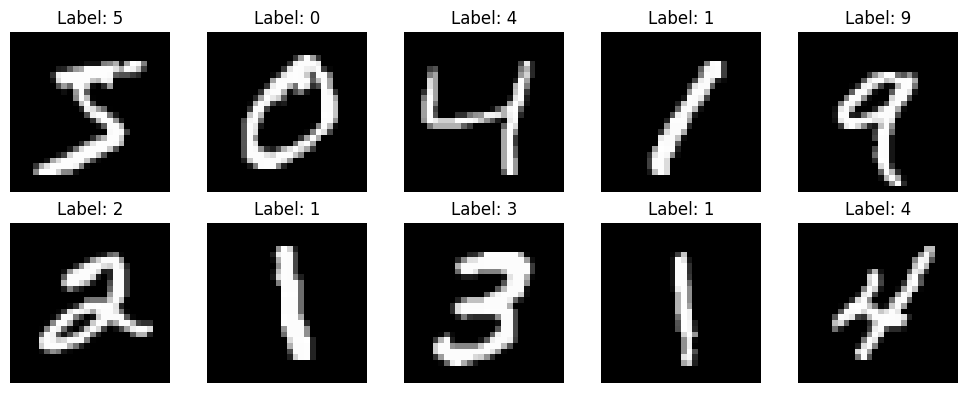

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):
    image, label = train_dataset[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Label: {label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class ANN(nn.Module):

    def __init__(self):
        super(ANN, self).__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model = ANN().to(device)

print(model)

ANN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
def get_task_data(dataset, digits):

    images = []
    labels = []

    for image, label in dataset:
        if label in digits:
            images.append(image)
            labels.append(label)

    images = torch.stack(images)
    labels = torch.tensor(labels)

    return images, labels


tasks = {}

for task_id in range(5):
    digits = [task_id * 2, task_id * 2 + 1]

    tasks[task_id] = get_task_data(
        train_dataset, digits
    )

    print(
        f"Task {task_id + 1}: Digits {digits}, "
        f"Samples: {len(tasks[task_id][1])}"
    )

Task 1: Digits [0, 1], Samples: 12665
Task 2: Digits [2, 3], Samples: 12089
Task 3: Digits [4, 5], Samples: 11263
Task 4: Digits [6, 7], Samples: 12183
Task 5: Digits [8, 9], Samples: 11800


In [ ]:
def train_model(model, images, labels, epochs=3):

    model.train()

    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):

        indices = torch.randperm(len(images))

        for start in range(0, len(images), 64):

            batch_indices = indices[start:start+64]

            x = images[batch_indices].to(device)
            y = labels[batch_indices].to(device)

            optimizer.zero_grad()

            outputs = model(x)
            loss = criterion(outputs, y)

            loss.backward()
            optimizer.step()

        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}")

In [ ]:
def evaluate_model(model, images, labels):

    model.eval()

    correct = 0
    total = len(labels)

    with torch.no_grad():

        for start in range(0, total, 64):

            x = images[start:start+64].to(device)
            y = labels[start:start+64].to(device)

            outputs = model(x)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == y).sum().item()

    accuracy = (correct / total) * 100

    return accuracy

In [ ]:
baseline_model = ANN().to(device)

baseline_results = {}

for task_id in range(5):

    images, labels = tasks[task_id]

    print(f"\nTraining Task {task_id + 1}")

    train_model(
        baseline_model,
        images,
        labels,
        epochs=3
    )

    for previous_task in range(task_id + 1):

        test_digits = [
            previous_task * 2,
            previous_task * 2 + 1
        ]

        test_images, test_labels = get_task_data(
            test_dataset, test_digits
        )

        accuracy = evaluate_model(
            baseline_model,
            test_images,
            test_labels
        )

        baseline_results[
            (task_id + 1, previous_task + 1)
        ] = accuracy

        print(
            f"Task {previous_task + 1} Accuracy: "
            f"{accuracy:.2f}%"
        )


Training Task 1
Epoch 1/3, Loss: 0.0049
Epoch 2/3, Loss: 0.0011
Epoch 3/3, Loss: 0.0039
Task 1 Accuracy: 99.95%

Training Task 2
Epoch 1/3, Loss: 0.2040
Epoch 2/3, Loss: 0.0542
Epoch 3/3, Loss: 0.0792
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 98.33%

Training Task 3
Epoch 1/3, Loss: 0.0547
Epoch 2/3, Loss: 0.0256
Epoch 3/3, Loss: 0.0018
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 0.00%
Task 3 Accuracy: 99.52%

Training Task 4
Epoch 1/3, Loss: 0.0022
Epoch 2/3, Loss: 0.0021
Epoch 3/3, Loss: 0.0002
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 0.00%
Task 3 Accuracy: 0.00%
Task 4 Accuracy: 99.80%

Training Task 5
Epoch 1/3, Loss: 0.0430
Epoch 2/3, Loss: 0.0446
Epoch 3/3, Loss: 0.0059
Task 1 Accuracy: 0.00%
Task 2 Accuracy: 0.00%
Task 3 Accuracy: 0.00%
Task 4 Accuracy: 0.00%
Task 5 Accuracy: 98.59%


In [ ]:
class SelfManagingMemory:

    def __init__(self, memory_per_class=50):
        self.memory = {}
        self.memory_per_class = memory_per_class

    def update(self, images, labels):

        for digit in torch.unique(labels):

            digit = digit.item()

            digit_images = images[labels == digit]

            combined = digit_images

            if digit in self.memory:
                combined = torch.cat(
                    [self.memory[digit], digit_images]
                )

            indices = torch.randperm(len(combined))

            selected = indices[:self.memory_per_class]

            self.memory[digit] = combined[selected]

    def get_memory(self):

        images = []
        labels = []

        for digit, stored_images in self.memory.items():

            images.extend(stored_images)
            labels.extend([digit] * len(stored_images))

        return torch.stack(images), torch.tensor(labels)

    def size(self):

        return sum(
            len(images) for images in self.memory.values()
        )


memory = SelfManagingMemory(memory_per_class=50)

print("Memory management system created!")

Memory management system created!


In [ ]:
memory_model = ANN().to(device)

memory_results = {}

for task_id in range(5):

    images, labels = tasks[task_id]

    print(f"\nTraining Task {task_id + 1}")

    if memory.size() > 0:

        old_images, old_labels = memory.get_memory()

        train_images = torch.cat([images, old_images])
        train_labels = torch.cat([labels, old_labels])

    else:

        train_images = images
        train_labels = labels

    train_model(
        memory_model,
        train_images,
        train_labels,
        epochs=3
    )

    memory.update(images, labels)

    print("Memory samples:", memory.size())

    for previous_task in range(task_id + 1):

        digits = [
            previous_task * 2,
            previous_task * 2 + 1
        ]

        test_images, test_labels = get_task_data(
            test_dataset, digits
        )

        accuracy = evaluate_model(
            memory_model,
            test_images,
            test_labels
        )

        memory_results[
            (task_id + 1, previous_task + 1)
        ] = accuracy

        print(
            f"Task {previous_task + 1} Accuracy: "
            f"{accuracy:.2f}%"
        )


Training Task 1
Epoch 1/3, Loss: 0.0006
Epoch 2/3, Loss: 0.0001
Epoch 3/3, Loss: 0.0003
Memory samples: 100
Task 1 Accuracy: 99.95%

Training Task 2
Epoch 1/3, Loss: 0.0416
Epoch 2/3, Loss: 0.0173
Epoch 3/3, Loss: 0.0393
Memory samples: 200
Task 1 Accuracy: 69.36%
Task 2 Accuracy: 98.04%

Training Task 3
Epoch 1/3, Loss: 0.4178
Epoch 2/3, Loss: 0.0324
Epoch 3/3, Loss: 0.0059
Memory samples: 300
Task 1 Accuracy: 84.07%
Task 2 Accuracy: 68.46%
Task 3 Accuracy: 99.79%

Training Task 4
Epoch 1/3, Loss: 0.0005
Epoch 2/3, Loss: 0.0092
Epoch 3/3, Loss: 0.0001
Memory samples: 400
Task 1 Accuracy: 75.41%
Task 2 Accuracy: 75.32%
Task 3 Accuracy: 50.85%
Task 4 Accuracy: 99.55%

Training Task 5
Epoch 1/3, Loss: 0.2316
Epoch 2/3, Loss: 0.0613
Epoch 3/3, Loss: 0.0223
Memory samples: 500
Task 1 Accuracy: 79.72%
Task 2 Accuracy: 64.10%
Task 3 Accuracy: 48.29%
Task 4 Accuracy: 67.72%
Task 5 Accuracy: 98.99%


Average Accuracy Comparison
After Task 1: Without Memory = 99.95%, With Memory = 99.95%
After Task 2: Without Memory = 49.17%, With Memory = 83.70%
After Task 3: Without Memory = 33.17%, With Memory = 84.11%
After Task 4: Without Memory = 24.95%, With Memory = 75.28%
After Task 5: Without Memory = 19.72%, With Memory = 71.77%


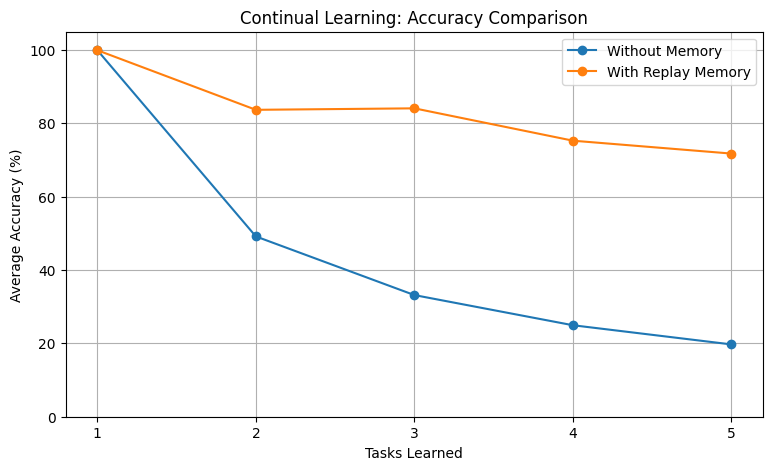


Average Forgetting
Without Memory: 99.4 percentage points
With Replay Memory: 34.37 percentage points


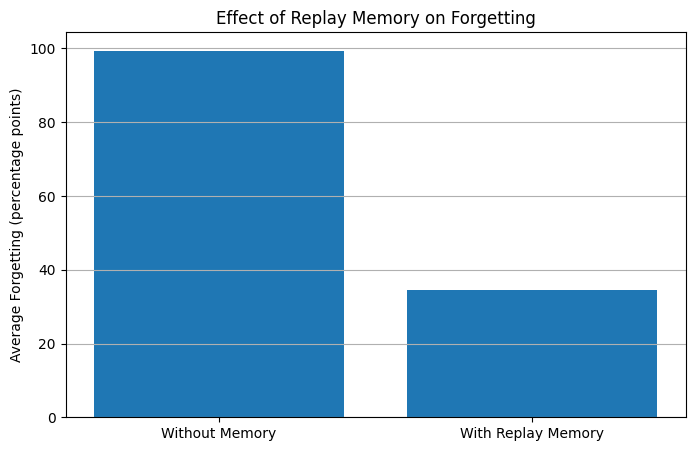

In [ ]:
# Average accuracy after each learning task

baseline_avg = []
memory_avg = []

for task in range(1, 6):

    baseline_scores = [
        baseline_results[(task, previous)]
        for previous in range(1, task + 1)
    ]

    memory_scores = [
        memory_results[(task, previous)]
        for previous in range(1, task + 1)
    ]

    baseline_avg.append(np.mean(baseline_scores))
    memory_avg.append(np.mean(memory_scores))


# Display comparison

print("Average Accuracy Comparison")

for i in range(5):
    print(
        f"After Task {i+1}: "
        f"Without Memory = {baseline_avg[i]:.2f}%, "
        f"With Memory = {memory_avg[i]:.2f}%"
    )


# Plot accuracy graph

plt.figure(figsize=(9, 5))

plt.plot(range(1, 6), baseline_avg,
         marker="o", label="Without Memory")

plt.plot(range(1, 6), memory_avg,
         marker="o", label="With Replay Memory")

plt.xlabel("Tasks Learned")
plt.ylabel("Average Accuracy (%)")
plt.title("Continual Learning: Accuracy Comparison")

plt.xticks(range(1, 6))
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.show()


# Calculate forgetting

baseline_forgetting = []
memory_forgetting = []

for task in range(1, 5):

    baseline_peak = baseline_results[(task, task)]
    baseline_final = baseline_results[(5, task)]

    memory_peak = memory_results[(task, task)]
    memory_final = memory_results[(5, task)]

    baseline_forgetting.append(baseline_peak - baseline_final)
    memory_forgetting.append(memory_peak - memory_final)


print("\nAverage Forgetting")

print(
    "Without Memory:",
    round(np.mean(baseline_forgetting), 2),
    "percentage points"
)

print(
    "With Replay Memory:",
    round(np.mean(memory_forgetting), 2),
    "percentage points"
)


# Plot forgetting comparison

plt.figure(figsize=(8, 5))

plt.bar(
    ["Without Memory", "With Replay Memory"],
    [
        np.mean(baseline_forgetting),
        np.mean(memory_forgetting)
    ]
)

plt.ylabel("Average Forgetting (percentage points)")
plt.title("Effect of Replay Memory on Forgetting")
plt.grid(axis="y")
plt.show()

In [ ]:
print("========== FINAL PROJECT RESULTS ==========")

print("\n1. FINAL AVERAGE ACCURACY")
print(f"Without Memory: {baseline_avg[-1]:.2f}%")
print(f"With Memory:    {memory_avg[-1]:.2f}%")

improvement = memory_avg[-1] - baseline_avg[-1]

print(f"Accuracy Improvement: {improvement:.2f} percentage points")


print("\n2. AVERAGE FORGETTING")

print(f"Without Memory: {np.mean(baseline_forgetting):.2f} pp")
print(f"With Memory:    {np.mean(memory_forgetting):.2f} pp")


print("\n3. MEMORY STORAGE")

print("Stored samples:", memory.size())
print("Maximum capacity:", 500)

image_storage_bytes = memory.size() * 28 * 28 * 4

print(
    "Approximate image storage:",
    round(image_storage_bytes / (1024 * 1024), 2),
    "MB"
)

print("\n========== EXPERIMENT COMPLETED ==========")

========== FINAL PROJECT RESULTS ==========

1. FINAL AVERAGE ACCURACY
Without Memory: 19.72%
With Memory:    71.77%
Accuracy Improvement: 52.05 percentage points

2. AVERAGE FORGETTING
Without Memory: 99.40 pp
With Memory:    34.37 pp

3. MEMORY STORAGE
Stored samples: 500
Maximum capacity: 500
Approximate image storage: 1.5 MB

========== EXPERIMENT COMPLETED ==========
